# Lid-Driven Cavity CFD: Ghia et al. Benchmark  

<!-- FLOWMLLAB_COLAB_LAUNCH_V1 -->
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ehsan-Roohi/FlowMLLab/blob/main/notebooks/week01/03_cavity_ghia.ipynb)
## Educational finite-difference streamfunction-vorticity solver

This notebook is the third Week-1 programming file.  
Now we use the Python tools from Notebook 1 to solve a real CFD benchmark.

Important scope:

- We solve only **Re = 100**.
- We use a **finite-difference streamfunction-vorticity method**.
- We do **not** use Lattice Boltzmann here.
- The goal is education: understand the algorithm, arrays, residuals, and validation.
- The benchmark is the classical lid-driven cavity data of Ghia, Ghia, and Shin.

The student should not treat this as a black-box CFD code.  
The notebook is organized so each solver component can be read and understood.

## Start with conservation of mass and momentum

We seek horizontal velocity $u(x,y,t)$, vertical velocity $v(x,y,t)$ and
pressure $p(x,y,t)$. For a Newtonian fluid with constant density $\rho$ and
dynamic viscosity $\mu$, the two-dimensional incompressible system is

$$
\frac{\partial u}{\partial x}+\frac{\partial v}{\partial y}=0,
$$

$$
\rho\left(\frac{\partial u}{\partial t}+u\frac{\partial u}{\partial x}
+v\frac{\partial u}{\partial y}\right)
=-\frac{\partial p}{\partial x}
+\mu\left(\frac{\partial^2u}{\partial x^2}+\frac{\partial^2u}{\partial y^2}\right),
$$

$$
\rho\left(\frac{\partial v}{\partial t}+u\frac{\partial v}{\partial x}
+v\frac{\partial v}{\partial y}\right)
=-\frac{\partial p}{\partial y}
+\mu\left(\frac{\partial^2v}{\partial x^2}+\frac{\partial^2v}{\partial y^2}\right).
$$

The first equation conserves mass. The next two conserve momentum in $x$ and
$y$. **Together they form the incompressible Navier–Stokes system.** Here
$x,y$ are spatial coordinates, $t$ is time, $\rho$ has units kg/m$^3$, $\mu$
has units Pa s, velocity has units m/s and pressure has units Pa. The kinematic
viscosity is $\nu=\mu/\rho$. Scaling lengths by cavity side $L$ and velocities
by lid speed $U$ gives $Re=UL/\nu$.

We derive the streamfunction–vorticity form from this system below. The
reference plots are evidence to inspect, not a replacement for that derivation.

## 0. Article-aligned validation: velocity **and** pressure

<!-- MIE690A article-aligned validation v3 -->

Before deriving the teaching solver, reproduce the two continuum validation figures used in the manuscript. This is a deliberate scientific order: define the evidence first, then study how the algorithm produces it.

1. **Velocity:** the retained $Re=400$ streamfunction--vorticity solution is compared directly with the Ghia *et al.* vertical-$u$ and horizontal-$v$ centerline markers.
2. **Pressure:** pressure is not a primary variable of this formulation. We reconstruct it from the steady nondimensional momentum gradients,

$$
p_x=-(u u_x+v u_y)+Re^{-1}\nabla^2u,\qquad
p_y=-(u v_x+v v_y)+Re^{-1}\nabla^2v,
$$

then solve one sparse least-squares edge-gradient system with a gauge constraint. The $Re=1000$ pressure centerlines are checked against Botella--Peyret, with both $65^2$ and $129^2$ executed grids shown. The simple solver is retained because every numerical step is inspectable by new students; the grid-refinement and literature errors state its limits rather than hiding them.

In [1]:
# FLOWMLLAB_COLAB_BOOTSTRAP_V1
# In Colab this cell obtains the complete repository and installs the tested package.
# In a local checkout it leaves the active environment and working directory unchanged.
from pathlib import Path as _FlowMLLabPath
import os as _flowmllab_os
import subprocess as _flowmllab_subprocess
import sys as _flowmllab_sys

if "google.colab" in _flowmllab_sys.modules or _flowmllab_os.environ.get("COLAB_RELEASE_TAG"):
    _flowmllab_root = _FlowMLLabPath("/content/FlowMLLab")
    if not (_flowmllab_root / ".git").is_dir():
        _flowmllab_subprocess.run(
            [
                "git", "clone", "--depth", "1",
                "https://github.com/Ehsan-Roohi/FlowMLLab.git", str(_flowmllab_root),
            ],
            check=True,
        )
    _flowmllab_subprocess.run(
        [
            _flowmllab_sys.executable, "-m", "pip", "install", "-q", "-e",
            f"{_flowmllab_root}[test]",
        ],
        check=True,
    )
    _flowmllab_notebook_dir = _flowmllab_root / "notebooks/week01"
    _flowmllab_os.chdir(_flowmllab_notebook_dir)
    for _flowmllab_path in (_flowmllab_root, _flowmllab_notebook_dir):
        if str(_flowmllab_path) not in _flowmllab_sys.path:
            _flowmllab_sys.path.insert(0, str(_flowmllab_path))
    print("FlowMLLab ready:", _flowmllab_root)

from pathlib import Path
import sys

def locate_course_root(start=Path.cwd()):
    for origin in (Path(start).resolve(), Path.cwd().resolve()):
        for candidate in (origin, *origin.parents):
            if (candidate / "common" / "article_validation.py").exists():
                return candidate
    raise FileNotFoundError(
        "Run this notebook inside the complete MIE690A release; common/article_validation.py is required."
    )

COURSE_ROOT = locate_course_root()
sys.path.insert(0, str(COURSE_ROOT / "common"))
from article_validation import (
    build_dsmc_wall_pressure_validation,
    build_ghia_velocity_validation,
    build_pressure_validation,
)
print("Course root:", COURSE_ROOT)


Course root: C:\Users\roohie\OneDrive - University of Massachusetts\Documents\Courses\FlowMLLab-week01_2


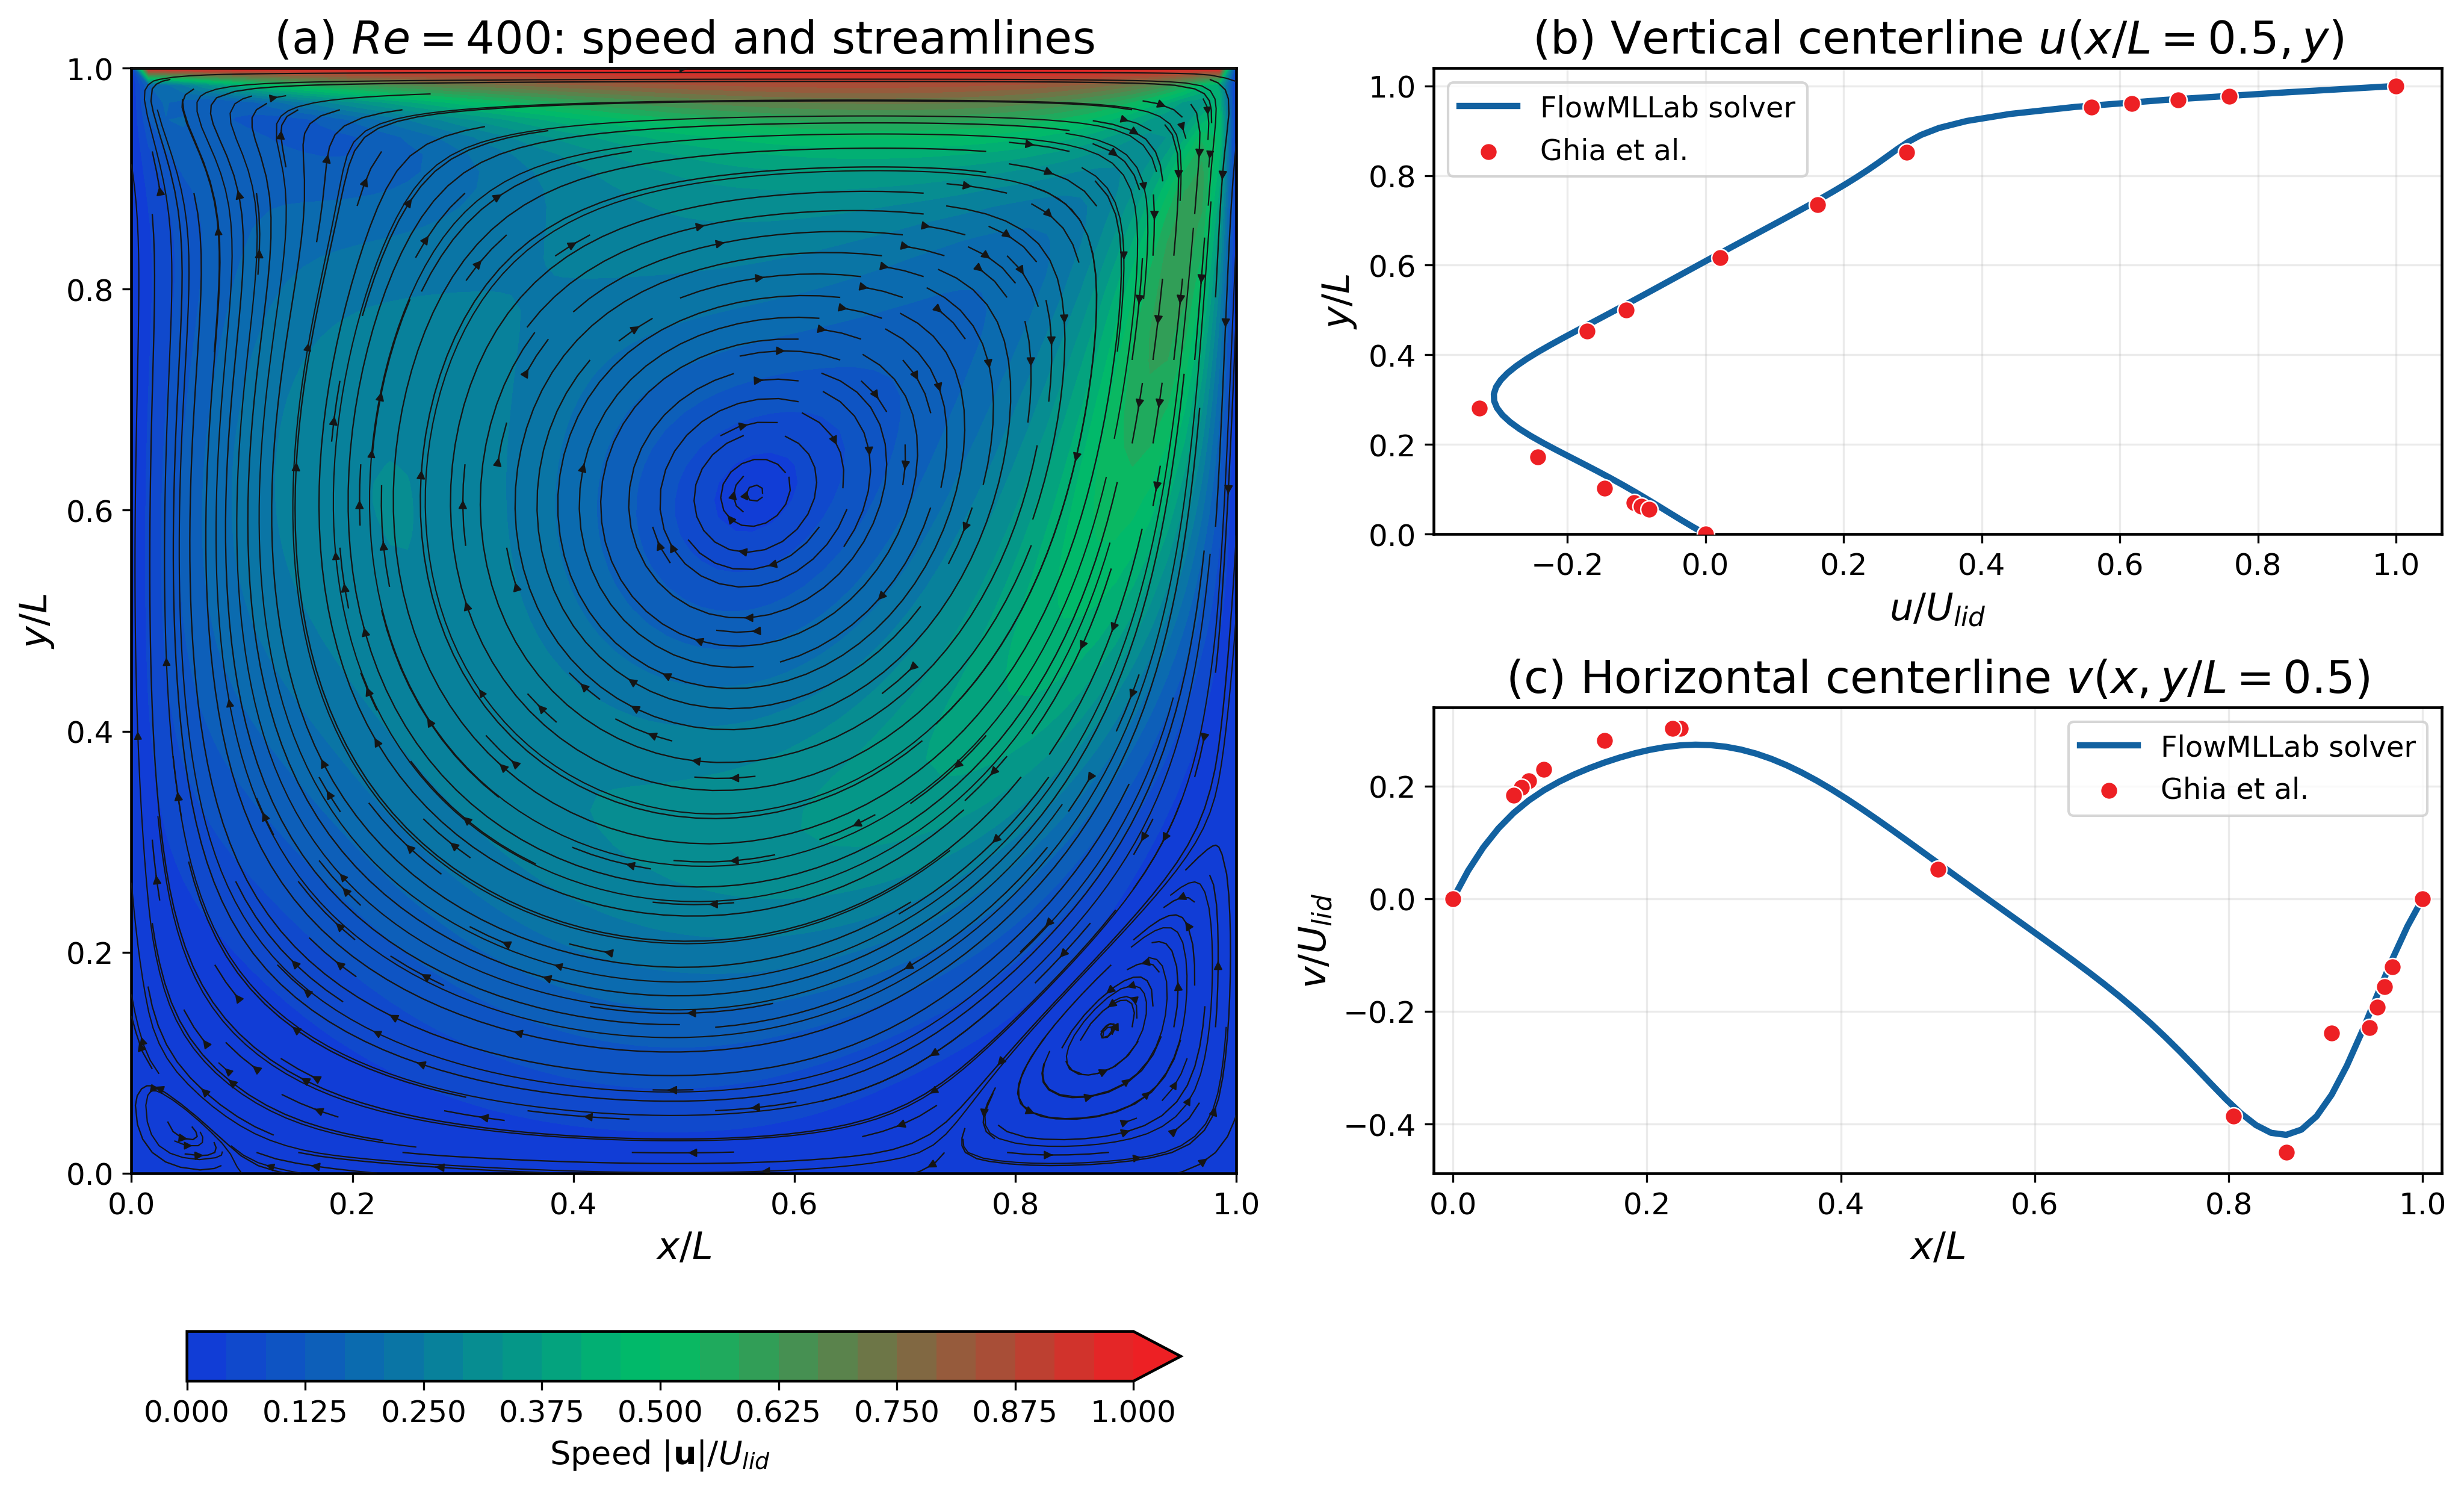

Re,u_centerline_relative_l2,v_centerline_relative_l2
400,0.052393,0.154259


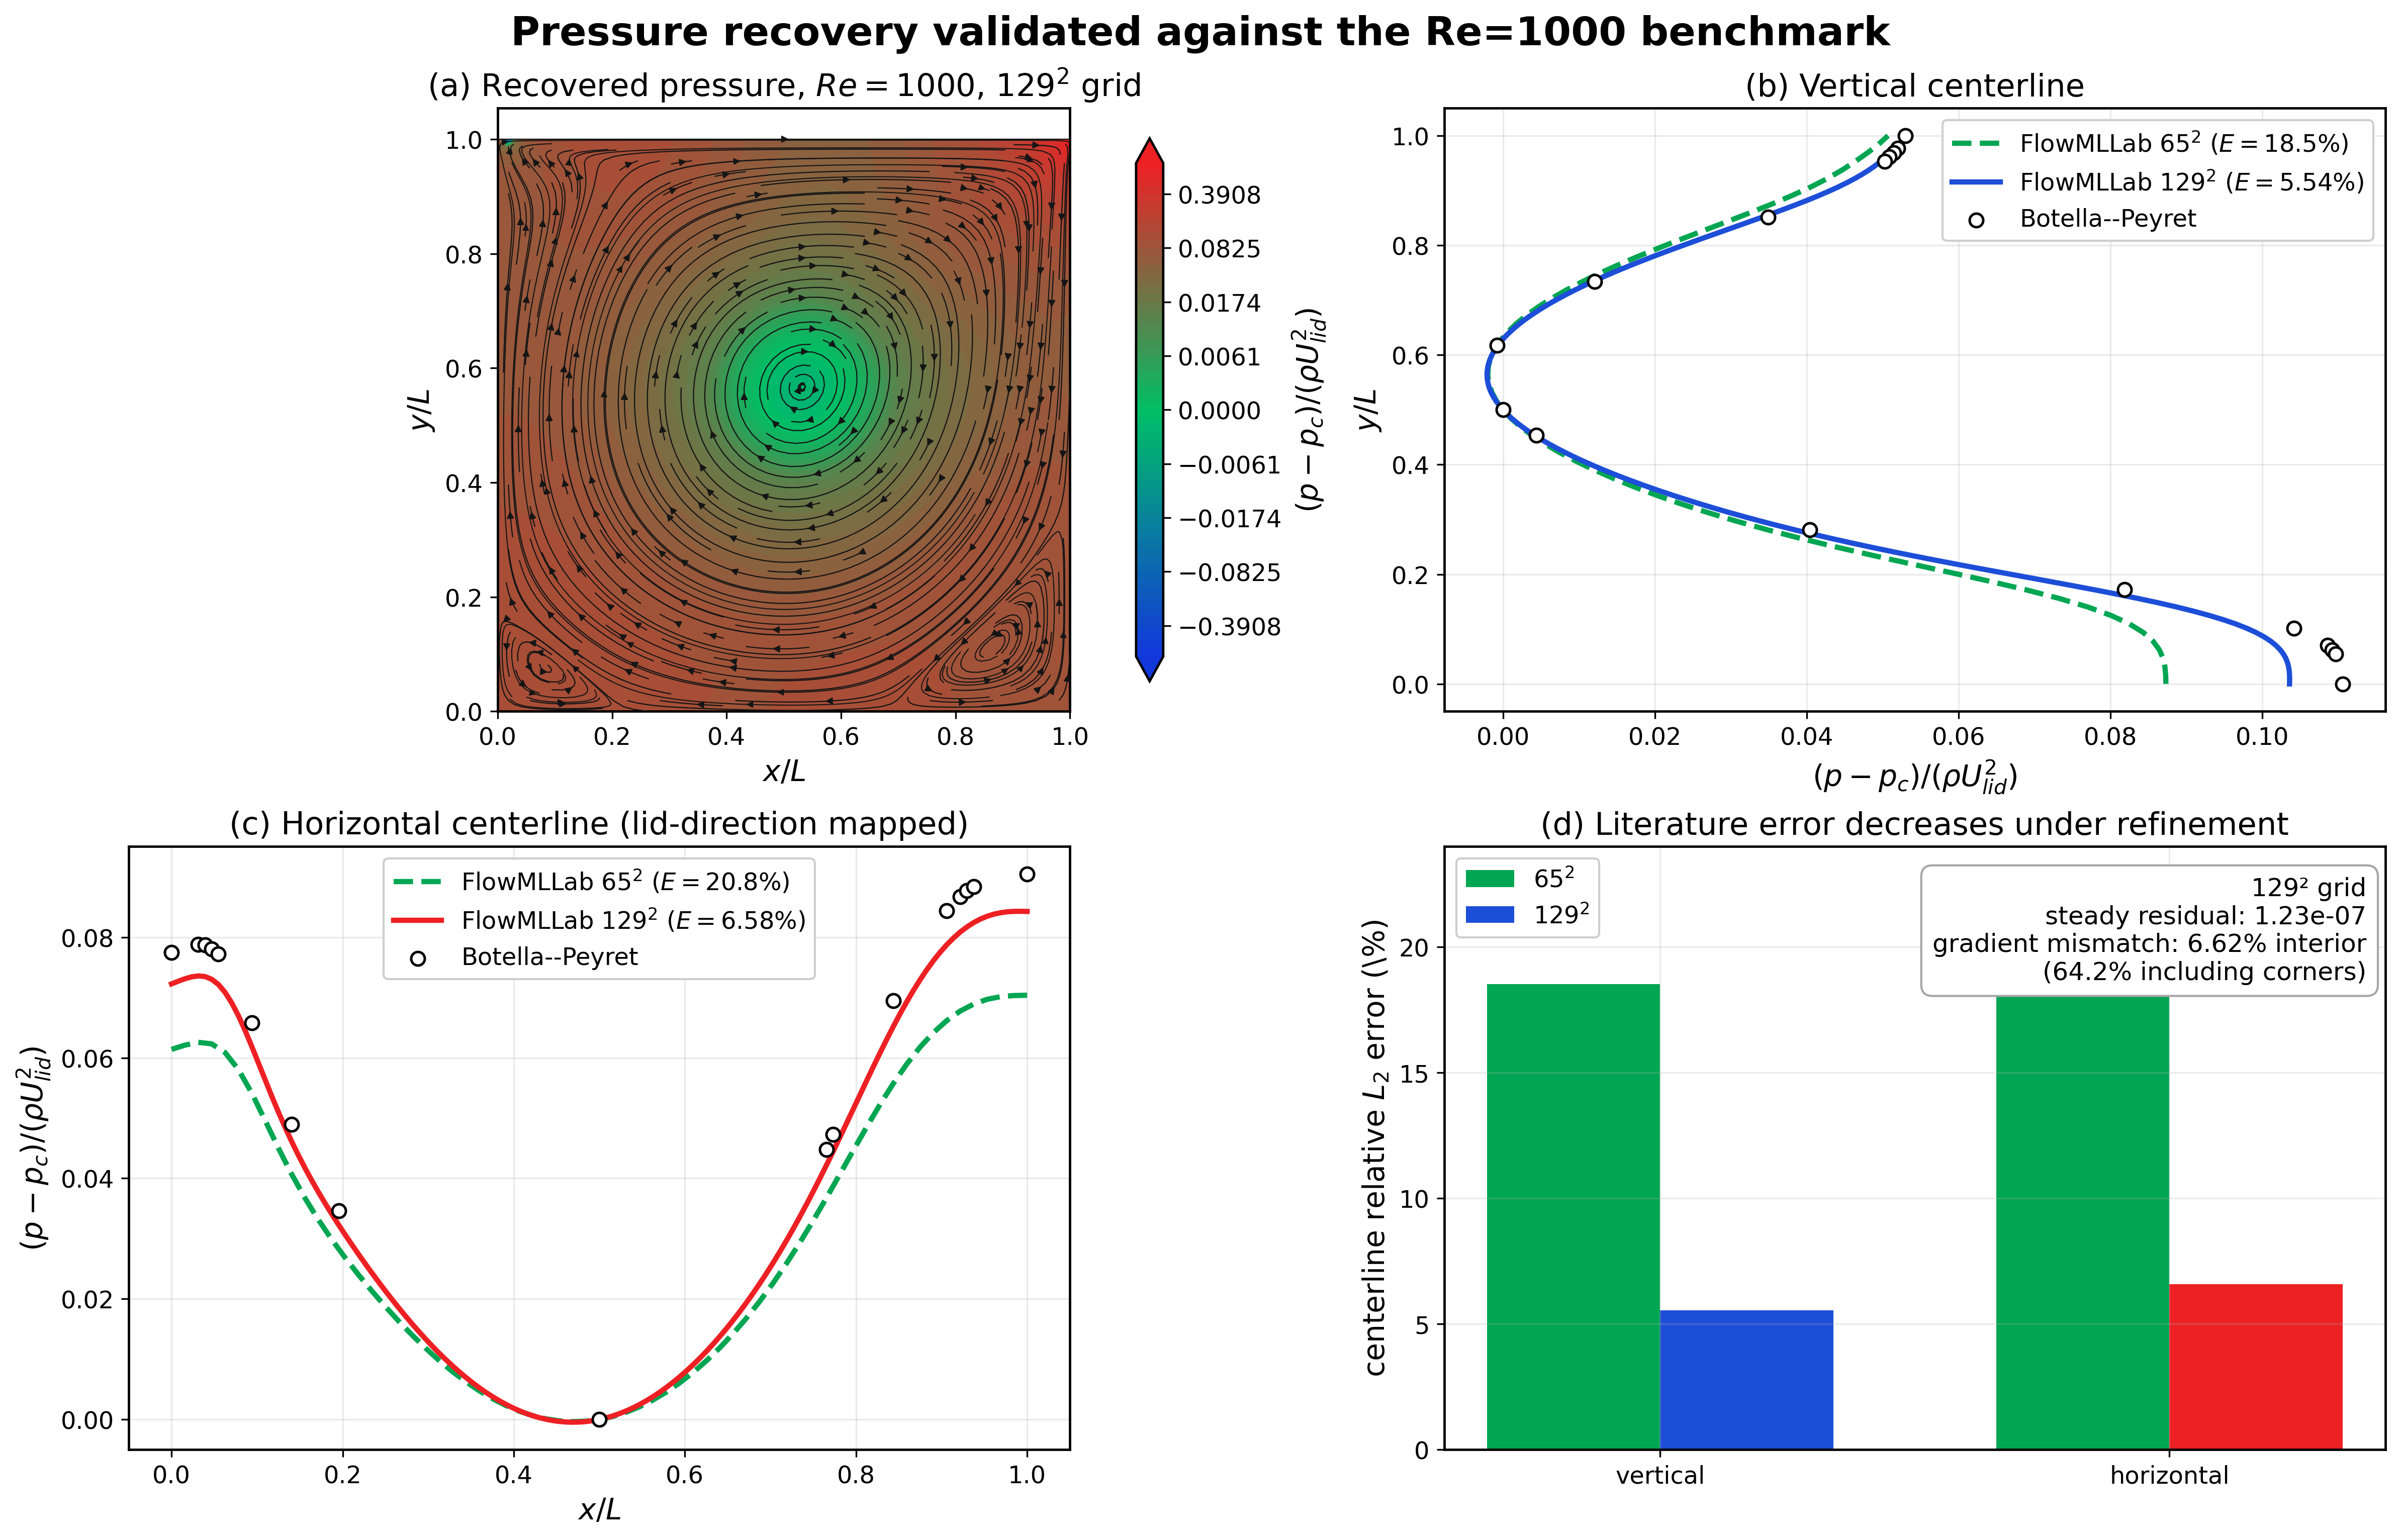

vertical_relative_l2_n65,vertical_relative_l2_n129,horizontal_relative_l2_n65,horizontal_relative_l2_n129,gradient_mismatch_interior,gradient_mismatch_global
0.185167,0.055376,0.207701,0.06575,0.06621,0.641532


Paper-ready files:
 - C:\Users\roohie\OneDrive - University of Massachusetts\Documents\Courses\FlowMLLab-week01_2\results\article_figures\fig02_cavity_benchmark.pdf
 - C:\Users\roohie\OneDrive - University of Massachusetts\Documents\Courses\FlowMLLab-week01_2\results\article_figures\fig08_pressure_recovery.pdf


In [2]:
from IPython.display import Image, display
import pandas as pd

STUDENT_OUTPUT = COURSE_ROOT / 'student_runs/article_validation'
velocity_validation = build_ghia_velocity_validation(COURSE_ROOT, STUDENT_OUTPUT)
pressure_validation = build_pressure_validation(COURSE_ROOT, STUDENT_OUTPUT)

display(Image(filename=str(velocity_validation["figure"]["png"]), width=1050))
display(pd.DataFrame([velocity_validation["metrics"]]))
display(Image(filename=str(pressure_validation["figure"]["png"]), width=1150))
display(pd.DataFrame([pressure_validation["metrics"]]))

print("Paper-ready files:")
print(" -", velocity_validation["figure"]["pdf"])
print(" -", pressure_validation["figure"]["pdf"])


In [3]:
# Optional production recomputation. The default uses the retained, executed runs so
# the notebook opens quickly and deterministically. Set True only when you intend to
# spend several minutes regenerating the two Re=1000 grids.
RECOMPUTE_PRESSURE_RUNS = False

if RECOMPUTE_PRESSURE_RUNS:
    import subprocess
    subprocess.run(
        [sys.executable, str(COURSE_ROOT / "common" / "run_cavity_pressure_validation.py")],
        cwd=COURSE_ROOT,
        check=True,
    )
    pressure_validation = build_pressure_validation(COURSE_ROOT, STUDENT_OUTPUT)
    display(Image(filename=str(pressure_validation["figure"]["png"]), width=1150))
else:
    print("Using retained Re=1000 N=65 and N=129 solver outputs; set the switch to rerun them.")


Using retained Re=1000 N=65 and N=129 solver outputs; set the switch to rerun them.


## 1. Physical problem

The lid-driven cavity is a square box filled with an incompressible viscous fluid.

Boundary conditions:

- top wall moves to the right with velocity $U=1$,
- bottom wall is stationary,
- left wall is stationary,
- right wall is stationary,
- no penetration at all walls.

The Reynolds number is

$$
Re=\frac{UL}{\nu}.
$$

Here $U=1$, $L=1$, and $Re=100$.  
Therefore $\nu=1/Re=0.01$.

This is a classical benchmark because it is simple to define but produces a nontrivial recirculating vortex.

## 2. From momentum and continuity to streamfunction and vorticity

The dimensional conservation equations are stated above. Scale position by cavity side $L$, velocity by lid speed $U$, time by $L/U$, and pressure difference by $\rho U^2$. The following derivation uses dimensionless variables and $Re=UL/\nu$.

For a smooth two-dimensional incompressible field in this simply connected cavity, define the streamfunction by

$$
u=\frac{\partial\psi}{\partial y},\qquad v=-\frac{\partial\psi}{\partial x}.
$$

Substituting these definitions into continuity gives zero because smooth mixed derivatives commute. Vorticity is $\omega=\partial v/\partial x-\partial u/\partial y$. Substitution of the streamfunction definitions gives

$$
\omega=-\frac{\partial^2\psi}{\partial x^2}-\frac{\partial^2\psi}{\partial y^2}.
$$

Thus $\nabla^2\psi=-\omega$. The vorticity evolution and pressure equations follow from the curl and divergence of momentum, respectively.

### 6: Vorticity transport from momentum conservation
**Governing equations.** Here $u(x,y,t)$ is horizontal velocity, $v(x,y,t)$ is vertical velocity, and $p(x,y,t)$ is pressure. All are dimensionless as defined in Section 3. Density and viscosity are constant, there is no body force, and $Re=UL/\nu$. The incompressible Navier-Stokes system is

$$
\underbrace{\frac{\partial u}{\partial x}+\frac{\partial v}{\partial y}=0}_{\text{continuity: conservation of mass}}.
$$

The two momentum equations are

$$
\frac{\partial u}{\partial t}
+u\frac{\partial u}{\partial x}+v\frac{\partial u}{\partial y}
=-\frac{\partial p}{\partial x}
+\frac{1}{Re}\left(\frac{\partial^2u}{\partial x^2}+\frac{\partial^2u}{\partial y^2}\right)
\qquad\text{(horizontal momentum)},
$$

$$
\frac{\partial v}{\partial t}
+u\frac{\partial v}{\partial x}+v\frac{\partial v}{\partial y}
=-\frac{\partial p}{\partial y}
+\frac{1}{Re}\left(\frac{\partial^2v}{\partial x^2}+\frac{\partial^2v}{\partial y^2}\right)
\qquad\text{(vertical momentum)}.
$$

Local acceleration, convection, pressure acceleration, and viscous diffusion appear in that order in each momentum equation. Continuity is an additional constraint on the same velocity fields.

**Vorticity.** The out-of-plane vorticity is

$$
\omega=\frac{\partial v}{\partial x}-\frac{\partial u}{\partial y}.
$$

We want a time-evolution equation for this particular difference of velocity derivatives. Therefore differentiate the *entire vertical momentum equation* with respect to $x$, differentiate the *entire horizontal momentum equation* with respect to $y$, and subtract the second result from the first. This operation is the out-of-plane component of the curl of momentum.

**Curl of the momentum equations.**

$$
\begin{aligned}
&\frac{\partial}{\partial x}\left(\frac{\partial v}{\partial t}\right)
-\frac{\partial}{\partial y}\left(\frac{\partial u}{\partial t}\right)\\
&\quad+\frac{\partial}{\partial x}\left(u\frac{\partial v}{\partial x}+v\frac{\partial v}{\partial y}\right)
-\frac{\partial}{\partial y}\left(u\frac{\partial u}{\partial x}+v\frac{\partial u}{\partial y}\right)\\
&=-\frac{\partial}{\partial x}\left(\frac{\partial p}{\partial y}\right)
+\frac{\partial}{\partial y}\left(\frac{\partial p}{\partial x}\right)\\
&\quad+\frac{1}{Re}\left[
\frac{\partial}{\partial x}\left(\frac{\partial^2v}{\partial x^2}+\frac{\partial^2v}{\partial y^2}\right)
-\frac{\partial}{\partial y}\left(\frac{\partial^2u}{\partial x^2}+\frac{\partial^2u}{\partial y^2}\right)\right].
\end{aligned}
$$

The transformed equation contains contributions from local acceleration, convection, pressure, and viscous diffusion.

### 6.1: Time derivatives and convective transport
**Commutation of mixed partial derivatives.** We assume the velocity and pressure fields have continuous mixed partial derivatives in the smooth interior. Under this assumption, differentiating first in time and then in space gives the same result as the reverse order. The derivative operators therefore commute:

$$
\begin{aligned}
\frac{\partial}{\partial x}\left(\frac{\partial v}{\partial t}\right)
-\frac{\partial}{\partial y}\left(\frac{\partial u}{\partial t}\right)
&=\frac{\partial}{\partial t}\left(\frac{\partial v}{\partial x}\right)
-\frac{\partial}{\partial t}\left(\frac{\partial u}{\partial y}\right)\\
&=\frac{\partial}{\partial t}\left(\frac{\partial v}{\partial x}-\frac{\partial u}{\partial y}\right)
=\frac{\partial\omega}{\partial t}.
\end{aligned}
$$

Likewise the pressure terms cancel because their mixed derivatives agree:

$$
-\frac{\partial^2p}{\partial x\,\partial y}
+\frac{\partial^2p}{\partial y\,\partial x}=0.
$$

Pressure has disappeared from this transformed equation; pressure itself can still vary in space.

**Product rule for convective terms.** For any two functions $a,b$, $\partial(ab)/\partial x=(\partial a/\partial x)b+a(\partial b/\partial x)$. The four products in the transformed equation give

$$
\begin{aligned}
\frac{\partial}{\partial x}\left(u\frac{\partial v}{\partial x}\right)
&=\frac{\partial u}{\partial x}\frac{\partial v}{\partial x}+u\frac{\partial^2v}{\partial x^2},\\
\frac{\partial}{\partial x}\left(v\frac{\partial v}{\partial y}\right)
&=\frac{\partial v}{\partial x}\frac{\partial v}{\partial y}+v\frac{\partial^2v}{\partial x\,\partial y},\\
\frac{\partial}{\partial y}\left(u\frac{\partial u}{\partial x}\right)
&=\frac{\partial u}{\partial y}\frac{\partial u}{\partial x}+u\frac{\partial^2u}{\partial y\,\partial x},\\
\frac{\partial}{\partial y}\left(v\frac{\partial u}{\partial y}\right)
&=\frac{\partial v}{\partial y}\frac{\partial u}{\partial y}+v\frac{\partial^2u}{\partial y^2}.
\end{aligned}
$$

The last two lines enter with minus signs. The terms multiplying $u$ combine into $u\,\partial\omega/\partial x$; those multiplying $v$ combine into $v\,\partial\omega/\partial y$. For example,

$$
u\left(\frac{\partial^2v}{\partial x^2}-\frac{\partial^2u}{\partial x\,\partial y}\right)
=u\frac{\partial}{\partial x}\left(\frac{\partial v}{\partial x}-\frac{\partial u}{\partial y}\right)
=u\frac{\partial\omega}{\partial x}.
$$

### 6.2: The cancellation and the final transport equation
**Continuity and the velocity-gradient products.** They factor as

$$
\begin{aligned}
&\frac{\partial u}{\partial x}\frac{\partial v}{\partial x}
+\frac{\partial v}{\partial x}\frac{\partial v}{\partial y}
-\frac{\partial u}{\partial y}\frac{\partial u}{\partial x}
-\frac{\partial v}{\partial y}\frac{\partial u}{\partial y}\\
&=\left(\frac{\partial u}{\partial x}+\frac{\partial v}{\partial y}\right)
\left(\frac{\partial v}{\partial x}-\frac{\partial u}{\partial y}\right)
=0\times\omega=0.
\end{aligned}
$$

The first bracket is zero by continuity. Neither individual velocity gradient nor individual product is assumed zero. Thus the complete convective contribution is

$$
u\frac{\partial\omega}{\partial x}+v\frac{\partial\omega}{\partial y}.
$$

**The viscous contribution remains.** Expand it and commute smooth mixed derivatives:

$$
\begin{aligned}
&\frac{1}{Re}\left[
\frac{\partial^3v}{\partial x^3}
+\frac{\partial^3v}{\partial x\,\partial y^2}
-\frac{\partial^3u}{\partial y\,\partial x^2}
-\frac{\partial^3u}{\partial y^3}\right]\\
&=\frac{1}{Re}\left[
\frac{\partial^2}{\partial x^2}\left(\frac{\partial v}{\partial x}-\frac{\partial u}{\partial y}\right)
+\frac{\partial^2}{\partial y^2}\left(\frac{\partial v}{\partial x}-\frac{\partial u}{\partial y}\right)\right]\\
&=\frac{1}{Re}\left(\frac{\partial^2\omega}{\partial x^2}+\frac{\partial^2\omega}{\partial y^2}\right).
\end{aligned}
$$

Combining the time, convection, pressure and viscous results gives

$$
\boxed{\frac{\partial\omega}{\partial t}
+u\frac{\partial\omega}{\partial x}+v\frac{\partial\omega}{\partial y}
=\frac{1}{Re}\left(\frac{\partial^2\omega}{\partial x^2}+\frac{\partial^2\omega}{\partial y^2}\right).}
$$

The left side describes local change and transport by fluid motion. The right side describes viscous spreading of vorticity. It is generally nonzero. In strictly two-dimensional motion there is no variation in $z$ and no out-of-plane velocity, so the three-dimensional vortex-stretching contribution is absent as well.

**Streamfunction coupling.** With $u=\partial\psi/\partial y$ and $v=-\partial\psi/\partial x$, the vorticity definition gives

$$
\frac{\partial^2\psi}{\partial x^2}+\frac{\partial^2\psi}{\partial y^2}=-\omega.
$$

The time-dependent vorticity equation and this spatial Poisson equation are solved together, with initial and wall conditions. They were derived from momentum and continuity; they do not replace the physical conservation laws with a new physical model.

### 6.3: Divergence of momentum and the pressure equation
**Divergence of viscous acceleration.** To derive an equation for pressure, take the $x$ derivative of horizontal momentum and add the $y$ derivative of vertical momentum. The viscous part of this operation is

$$
\begin{aligned}
\frac{1}{Re}\left[
\frac{\partial}{\partial x}\left(\frac{\partial^2u}{\partial x^2}+\frac{\partial^2u}{\partial y^2}\right)
+\frac{\partial}{\partial y}\left(\frac{\partial^2v}{\partial x^2}+\frac{\partial^2v}{\partial y^2}\right)\right].
\end{aligned}
$$

This is the four-term expression obtained by taking the divergence of viscous acceleration. Keep all four terms and regroup them:

$$
\begin{aligned}
&\frac{\partial^3u}{\partial x^3}
+\frac{\partial^3u}{\partial x\,\partial y^2}
+\frac{\partial^3v}{\partial y\,\partial x^2}
+\frac{\partial^3v}{\partial y^3}\\
&=\frac{\partial^2}{\partial x^2}\left(\frac{\partial u}{\partial x}\right)
+\frac{\partial^2}{\partial y^2}\left(\frac{\partial u}{\partial x}\right)
+\frac{\partial^2}{\partial x^2}\left(\frac{\partial v}{\partial y}\right)
+\frac{\partial^2}{\partial y^2}\left(\frac{\partial v}{\partial y}\right)\\
&=\frac{\partial^2}{\partial x^2}\underbrace{\left(\frac{\partial u}{\partial x}+\frac{\partial v}{\partial y}\right)}_{0\text{ by continuity}}
+\frac{\partial^2}{\partial y^2}\underbrace{\left(\frac{\partial u}{\partial x}+\frac{\partial v}{\partial y}\right)}_{0\text{ by continuity}}=0.
\end{aligned}
$$

Commutation of smooth mixed derivatives justifies the second line. Continuity justifies the last line. Omitting either mixed term would invalidate the cancellation.

**Pressure-Poisson equation.** The time terms similarly sum to $\partial(\partial u/\partial x+\partial v/\partial y)/\partial t=0$. The remaining pressure and convection terms give

$$
\begin{aligned}
\frac{\partial^2p}{\partial x^2}+\frac{\partial^2p}{\partial y^2}
=-\left[\left(\frac{\partial u}{\partial x}\right)^2
+2\frac{\partial u}{\partial y}\frac{\partial v}{\partial x}
+\left(\frac{\partial v}{\partial y}\right)^2\right].
\end{aligned}
$$

Section 12 derives the convective expansion and pressure boundary conditions. The pressure equation is a consequence of the same momentum equations, not a new momentum equation.

**Curl and divergence.** Curl of momentum produces a difference of velocity derivatives, $\omega$, and retains viscous diffusion. Divergence of momentum produces the sum in continuity, which is zero, and eliminates the interior divergence of viscous acceleration for this constant-property fluid. The two operations yield different equations.
**Check your understanding.** Write the two derivative operations in words. Which uses a subtraction and produces vorticity? Which uses an addition and produces the pressure equation?

In [4]:
import numpy as np
import matplotlib.pyplot as plt
# Consistent field and profile plotting.
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler
if "cavity_rgb" not in mpl.colormaps:
    mpl.colormaps.register(LinearSegmentedColormap.from_list(
        "cavity_rgb", ["#1238db", "#00bf65", "#ed2024"], N=256))
plt.rcParams.update({"image.cmap": "cavity_rgb",
                     "axes.prop_cycle": cycler(color=["#1238db", "#00a652", "#ed2024"])})

from pathlib import Path

# Ghia et al. Re=100 benchmark data
GHIA_Y = np.array([
    1.0000, 0.9766, 0.9688, 0.9609, 0.9531,
    0.8516, 0.7344, 0.6172, 0.5000, 0.4531,
    0.2813, 0.1719, 0.1016, 0.0703, 0.0625,
    0.0547, 0.0000
])

GHIA_U = np.array([
    1.00000, 0.84123, 0.78871, 0.73722, 0.68717,
    0.23151, 0.00332, -0.13641, -0.20581, -0.21090,
    -0.15662, -0.10150, -0.06434, -0.04775, -0.04192,
    -0.03717, 0.00000
])

GHIA_X = np.array([
    1.0000, 0.9688, 0.9609, 0.9531, 0.9453,
    0.9063, 0.8594, 0.8047, 0.5000, 0.2344,
    0.2266, 0.1563, 0.0938, 0.0781, 0.0703,
    0.0625, 0.0000
])

GHIA_V = np.array([
    0.00000, -0.05906, -0.07391, -0.08864, -0.10313,
    -0.16914, -0.22445, -0.24533, 0.05454, 0.17527,
    0.17507, 0.16077, 0.12317, 0.10890, 0.10091,
    0.09233, 0.00000
])

## 3. Build the grid

We use a square grid with $N\times N$ points.

For the required Week-1 run, use:

$$
N=65.
$$

This is not a publication-quality grid. It is a teaching grid:
- small enough to run quickly,
- large enough to compare with Ghia,
- simple enough for students to inspect.

In [5]:
def build_grid(N):
    x = np.linspace(0.0, 1.0, N)
    y = np.linspace(0.0, 1.0, N)
    X, Y = np.meshgrid(x, y)
    dx = x[1] - x[0]
    dy = y[1] - y[0]
    return x, y, X, Y, dx, dy

N = 65
x, y, X, Y, dx, dy = build_grid(N)

print("Grid size:", N, "x", N)
print("dx =", dx)
print("dy =", dy)

Grid size: 65 x 65
dx = 0.015625
dy = 0.015625


## 4. Finite-difference operators

We need:
- first derivatives for convection,
- Laplacian for diffusion,
- Poisson solve for streamfunction.

The Laplacian stencil is the same one learned in the Python notebook.

In [6]:
def laplacian(phi, dx, dy):
    lap = np.zeros_like(phi)
    lap[1:-1, 1:-1] = (
        (phi[1:-1, 2:] - 2.0*phi[1:-1, 1:-1] + phi[1:-1, :-2]) / dx**2
        + (phi[2:, 1:-1] - 2.0*phi[1:-1, 1:-1] + phi[:-2, 1:-1]) / dy**2
    )
    return lap

## 5. Boundary conditions for vorticity

For the streamfunction, the walls are streamlines. We set:

$$
\psi = 0
$$

on all walls.

The wall vorticity is not directly specified. It is inferred from the no-slip condition using a finite-difference wall formula. For the moving lid, the formula includes the lid velocity $U$.

This is one of the most important parts of the code. If the wall vorticity is wrong, the whole cavity solution becomes wrong.

In [7]:
def apply_vorticity_boundary_conditions(psi, omega, U, dx, dy):
    # Bottom wall: stationary
    omega[0, 1:-1] = -2.0 * psi[1, 1:-1] / dy**2

    # Top wall: moving lid with u = U
    omega[-1, 1:-1] = -2.0 * psi[-2, 1:-1] / dy**2 - 2.0 * U / dy

    # Left wall: stationary
    omega[1:-1, 0] = -2.0 * psi[1:-1, 1] / dx**2

    # Right wall: stationary
    omega[1:-1, -1] = -2.0 * psi[1:-1, -2] / dx**2

    # Corner values: simple averages of neighboring wall values
    omega[0, 0] = 0.5 * (omega[0, 1] + omega[1, 0])
    omega[0, -1] = 0.5 * (omega[0, -2] + omega[1, -1])
    omega[-1, 0] = 0.5 * (omega[-1, 1] + omega[-2, 0])
    omega[-1, -1] = 0.5 * (omega[-1, -2] + omega[-2, -1])

    return omega

## 6. Solve the streamfunction Poisson equation

At each time step, vorticity $\omega$ is known and we solve:

$$
\nabla^2 \psi = -\omega.
$$

We use Jacobi iterations. This is simple and educational, although not the fastest method.

### 7.2: Taylor expansions and the two-dimensional stencil
**Field samples on the grid.** At a fixed time, sample a smooth scalar field $f(x,y)$ on a rectangular grid. Coordinates are $x_i=x_0+i\Delta x$, $y_j=y_0+j\Delta y$. We store $f_{j,i}=f(x_i,y_j)$: array row $j$ corresponds to $y$, and array column $i$ corresponds to $x$.

**Expansion in the horizontal direction.** Name the center $C=f(x_i,y_j)$, its east neighbor $E=f(x_i+\Delta x,y_j)$, and its west neighbor $W=f(x_i-\Delta x,y_j)$. Taylor expansion about the same center gives

$$
\begin{aligned}
E&=C+\Delta x\frac{\partial f}{\partial x}
+\frac{\Delta x^2}{2}\frac{\partial^2f}{\partial x^2}
+\frac{\Delta x^3}{6}\frac{\partial^3f}{\partial x^3}+O(\Delta x^4),\\
W&=C-\Delta x\frac{\partial f}{\partial x}
+\frac{\Delta x^2}{2}\frac{\partial^2f}{\partial x^2}
-\frac{\Delta x^3}{6}\frac{\partial^3f}{\partial x^3}+O(\Delta x^4).
\end{aligned}
$$

All derivatives on these right sides are evaluated at $(x_i,y_j)$. Adding the equations cancels the odd powers:

$$
E+W=2C+\Delta x^2\frac{\partial^2f}{\partial x^2}+O(\Delta x^4).
$$

Subtract $2C$ and divide by $\Delta x^2$:

$$
\boxed{\left.\frac{\partial^2f}{\partial x^2}\right|_{(x_i,y_j)}
=\frac{E-2C+W}{\Delta x^2}+O(\Delta x^2).}
$$

This explains the coefficient $-2$: each neighbor expansion contains one center value, so their sum contains $2C$. It also explains the denominator: a second derivative requires division by the square of the spacing.

**Expansion in the vertical direction.** Let $N=f(x_i,y_j+\Delta y)$ and $S=f(x_i,y_j-\Delta y)$. The same calculation gives

$$
\begin{aligned}
N&=C+\Delta y\frac{\partial f}{\partial y}+\frac{\Delta y^2}{2}\frac{\partial^2f}{\partial y^2}+\frac{\Delta y^3}{6}\frac{\partial^3f}{\partial y^3}+O(\Delta y^4),\\
S&=C-\Delta y\frac{\partial f}{\partial y}+\frac{\Delta y^2}{2}\frac{\partial^2f}{\partial y^2}-\frac{\Delta y^3}{6}\frac{\partial^3f}{\partial y^3}+O(\Delta y^4).
\end{aligned}
$$

The cubic terms have opposite signs and cancel on addition, just as in $x$. Thus

$$
\boxed{\left.\frac{\partial^2f}{\partial y^2}\right|_{(x_i,y_j)}
=\frac{N-2C+S}{\Delta y^2}+O(\Delta y^2).}
$$

A second derivative measures curvature, not upward or downward velocity. The letters $N,S,E,W$ identify locations; they are not signed physical quantities.

### 7.2 continued: The five-point Laplacian and array indexing
The Laplacian is defined as the sum of the two second derivatives:

$$
\nabla^2 f=\frac{\partial^2f}{\partial x^2}+\frac{\partial^2f}{\partial y^2}.
$$

Substitute the two formulas just derived. Denote the resulting numerical approximation by $L_h f$:

$$
\begin{aligned}
L_hf&=\frac{E-2C+W}{\Delta x^2}+\frac{N-2C+S}{\Delta y^2}.\\
\text{If }\Delta x=\Delta y=h,\qquad
L_hf&=\frac{E-2C+W+N-2C+S}{h^2}\\
&=\boxed{\frac{E+W+N+S-4C}{h^2}}.
\end{aligned}
$$

The center coefficient is $-4$ because the $x$ and $y$ formulas each contribute $-2C$. The approximation error is $O(\Delta x^2+\Delta y^2)$ for smooth fields. A stencil lists the locations and weights in this approximation; no diagonal neighbors are needed here.

```text
             N = f[j+1,i]
                  |
W = f[j,i-1] - C = f[j,i] - E = f[j,i+1]
                  |
             S = f[j-1,i]
```

**Polynomial example.** For $f=x^2+3y^2$, center $(0.5,0.5)$, and $h=0.1$, the five values are $(C,E,W,N,S)=(1,1.11,0.91,1.33,0.73)$. Therefore

$$
\frac{E-2C+W}{h^2}=\frac{1.11-2+0.91}{0.01}=2,\qquad
\frac{N-2C+S}{h^2}=\frac{1.33-2+0.73}{0.01}=6.
$$

Their sum is $8$, equal to the exact Laplacian $2+6$. This is a derivative check, not a cavity flow solution.

**Vectorized stencil evaluation.**

| Location | Single entry | All interior-aligned entries |
| -- | -- | -- |
| Center | f[j,i] | f[1:-1,1:-1] |
| East | f[j,i+1] | f[1:-1,2:] |
| West | f[j,i-1] | f[1:-1,:-2] |
| North | f[j+1,i] | f[2:,1:-1] |
| South | f[j-1,i] | f[:-2,1:-1] |

Each block has shape $(N_y-2,N_x-2)$. In Python, `1:-1` excludes both boundaries. Every output entry combines its own five neighboring samples. The code's zero placeholders on the outer boundary are not a physical assertion about the wall Laplacian.

### 7.3: From the Poisson equation to an iteration
**Streamfunction Poisson equation.** The streamfunction equation derived in Section 5 is

$$
\frac{\partial^2\psi}{\partial x^2}+\frac{\partial^2\psi}{\partial y^2}=-\omega.
$$

Vorticity $\omega$ is held fixed during this Poisson solve. Insert the second-difference formulas at one interior node:

$$
\frac{\psi_E-2\psi_C+\psi_W}{\Delta x^2}
+\frac{\psi_N-2\psi_C+\psi_S}{\Delta y^2}=-\omega_C.
$$

Multiply every term by $\Delta x^2\Delta y^2$ and collect the center terms:

$$
\begin{aligned}
&\Delta y^2(\psi_E+\psi_W)-2\Delta y^2\psi_C
+\Delta x^2(\psi_N+\psi_S)-2\Delta x^2\psi_C
=-\omega_C\Delta x^2\Delta y^2,\\
&2(\Delta x^2+\Delta y^2)\psi_C
=\Delta y^2(\psi_E+\psi_W)+\Delta x^2(\psi_N+\psi_S)
+\omega_C\Delta x^2\Delta y^2.
\end{aligned}
$$

Divide by the coefficient of $\psi_C$. This is an algebraic rearrangement, not yet a new time step:

$$
\psi_C=\frac{\Delta y^2(\psi_E+\psi_W)+\Delta x^2(\psi_N+\psi_S)
+\omega_C\Delta x^2\Delta y^2}{2(\Delta x^2+\Delta y^2)}.
$$

**Why iterate?** The four neighboring interior values are also unknown. Start with a guess and repeatedly use the previous sweep's neighbors. If $k$ counts these Jacobi sweeps, the update implemented by the notebook is

$$
\psi_{j,i}^{k+1}=\frac{(\psi^k_{j,i+1}+\psi^k_{j,i-1})\Delta y^2
+(\psi^k_{j+1,i}+\psi^k_{j-1,i})\Delta x^2
+\omega_{j,i}\Delta x^2\Delta y^2}{2(\Delta x^2+\Delta y^2)}.
$$

The superscript $k$ is an iteration counter, not an exponent and not physical time. The subscript $j,i$ is a grid location. The current $\omega$ and prescribed boundary values do not change during these inner sweeps.

**Equal spacing gives a simpler row.** With $\Delta x=\Delta y=h$, multiply the discrete Poisson equation by $h^2$:

$$
\begin{aligned}
\psi_E+\psi_W+\psi_N+\psi_S-4\psi_C&=-h^2\omega_C,\\
4\psi_C-\psi_E-\psi_W-\psi_N-\psi_S&=h^2\omega_C,\\
\psi_C^{k+1}&=\tfrac14(\psi_E^k+\psi_W^k+\psi_N^k+\psi_S^k+h^2\omega_C).
\end{aligned}
$$

The positive vorticity term in the update follows from rearranging $\nabla^2\psi=-\omega$. It is not an arbitrary sign choice.

### 7.3 continued: A four-node Poisson system
**Grid, source, and boundary data.** Use the unit square with grid coordinates $0,1/3,2/3,1$ in each direction. Thus $h=1/3$, $h^2=1/9$, and there are four interior unknowns. Prescribe $\psi=0$ at every boundary node and $\omega=-2$ at each interior node. Label the unknowns by location:

| $y\backslash x$ | $0$ | $1/3$ | $2/3$ | $1$ |
| -- | -- | -- | -- | -- |
| $1$ | $0$ | $0$ | $0$ | $0$ |
| $2/3$ | $0$ | $c$ | $d$ | $0$ |
| $1/3$ | $0$ | $a$ | $b$ | $0$ |
| $0$ | $0$ | $0$ | $0$ | $0$ |

Each row comes from $4\psi_C-\psi_E-\psi_W-\psi_N-\psi_S=h^2\omega_C$. Here every right side is $(1/9)(-2)=-2/9$. Substitute the neighbors individually:

$$
\begin{aligned}
\text{At }a:\quad4a-\underbrace{b}_{E}-\underbrace{0}_{W}-\underbrace{c}_{N}-\underbrace{0}_{S}&=-2/9,\\
\text{At }b:\quad4b-\underbrace{0}_{E}-\underbrace{a}_{W}-\underbrace{d}_{N}-\underbrace{0}_{S}&=-2/9,\\
\text{At }c:\quad4c-\underbrace{d}_{E}-\underbrace{0}_{W}-\underbrace{0}_{N}-\underbrace{a}_{S}&=-2/9,\\
\text{At }d:\quad4d-\underbrace{0}_{E}-\underbrace{c}_{W}-\underbrace{0}_{N}-\underbrace{b}_{S}&=-2/9.
\end{aligned}
$$

Now choose the unknown vector in the order $(a,b,c,d)$. Read each equation's coefficients in that same order:

$$
\begin{array}{rcr}
4a-b-c+0d&=&-2/9,\\
-a+4b+0c-d&=&-2/9,\\
-a+0b+4c-d&=&-2/9,\\
0a-b-c+4d&=&-2/9.
\end{array}
\quad\Longrightarrow\quad
\begin{bmatrix}
4&-1&-1&0\\-1&4&0&-1\\-1&0&4&-1\\0&-1&-1&4
\end{bmatrix}
\begin{bmatrix}a\\b\\c\\d\end{bmatrix}
=\begin{bmatrix}-2/9\\-2/9\\-2/9\\-2/9\end{bmatrix}.
$$

The diagonal $4$ belongs to the center. A coefficient $-1$ belongs to an interior cardinal neighbor. A zero means that unknown is not a neighbor in that row. In $A\boldsymbol q=\boldsymbol b$, $A$ is this coefficient matrix, $\boldsymbol q=(a,b,c,d)^T$ is the unknown vector, and $\boldsymbol b$ is the known right side. This $\boldsymbol b$ is a vector, distinct from the scalar grid value named $b$.

**If a wall value were nonzero**, it would enter the known right side. For example, west boundary $g_W$ and south boundary $g_S$ at node $a$ give $4a-b-c=-2/9+g_W+g_S$. The wall data have not been ignored; they are zero in the chosen example.

### 7.3 continued: Solution and Jacobi convergence
**Exact solution of the discrete system.** All four equations have identical data and symmetric positions. Setting $a=b=c=d=s$ reduces each row to $4s-s-s=2s=-2/9$, giving $s=-1/9$. For example, the first row gives

$$
4(-1/9)-(-1/9)-(-1/9)=-2/9.
$$

This satisfies every row; the discrete Dirichlet Poisson matrix is nonsingular, so this is the unique solution. Prescribed $\omega=-2$ is a demonstration input, not the vorticity from a complete no-slip cavity run.

**Jacobi iteration.** Isolate each diagonal term and use only the preceding sweep's neighbors:

$$
\begin{aligned}
a^{k+1}&=\tfrac14(b^k+c^k-2/9),&
b^{k+1}&=\tfrac14(a^k+d^k-2/9),\\
c^{k+1}&=\tfrac14(a^k+d^k-2/9),&
d^{k+1}&=\tfrac14(b^k+c^k-2/9).
\end{aligned}
$$

Start from $a^0=b^0=c^0=d^0=0$. The first sweep is

$$
a^1=b^1=c^1=d^1=\tfrac14(0+0-2/9)=-1/18.
$$

The second sweep uses $-1/18$ from the first sweep at both neighbors:

$$
a^2=\tfrac14(-1/18-1/18-2/9)=-1/12,
$$

and the other three entries have the same value. Continuing gives

| Sweep $k$ | Each interior value | Absolute error relative to $-1/9$ |
| -- | -- | -- |
| 0 | $0$ | $1/9$ |
| 1 | $-1/18$ | $1/18$ |
| 2 | $-1/12$ | $1/36$ |
| 3 | $-7/72$ | $1/72$ |
| $\infty$ | $-1/9$ | $0$ |

**Implementation.** The notebook uses `old = psi.copy()` to retain the previous sweep. Its center slice is assigned the update derived above, using four neighbor slices from `old`. Reusing a newly updated neighbor within a point-by-point loop would instead produce a Gauss-Seidel sweep.

**Inner iteration and physical time.** During these inner iterations, the streamfunction guess changes; vorticity, wall values, mesh, and physical time stay fixed. After the Poisson solve, the outer algorithm obtains velocity from streamfunction and advances vorticity in time. A new vorticity field requires another Poisson solve.
**Check your understanding.** Recover the third matrix row by listing the four neighbors of $c$. Then change only its north boundary value to $0.1$ and write the new right side. Answer: $-2/9+0.1$.

In [8]:
def solve_streamfunction_poisson(psi, omega, dx, dy, iterations=60):
    dx2 = dx**2
    dy2 = dy**2
    denom = 2.0 * (dx2 + dy2)

    for _ in range(iterations):
        old = psi.copy()

        psi[1:-1, 1:-1] = (
            (old[1:-1, 2:] + old[1:-1, :-2]) * dy2
            + (old[2:, 1:-1] + old[:-2, 1:-1]) * dx2
            + omega[1:-1, 1:-1] * dx2 * dy2
        ) / denom

        # Streamfunction is zero on the walls
        psi[0, :] = 0.0
        psi[-1, :] = 0.0
        psi[:, 0] = 0.0
        psi[:, -1] = 0.0

    return psi

## 7. Compute velocity from streamfunction

The velocity is computed from:

$$
u = \frac{\partial\psi}{\partial y},
\qquad
v = -\frac{\partial\psi}{\partial x}.
$$

Then the boundary velocities are imposed explicitly:
- top lid: $u=U,\;v=0$,
- other walls: $u=v=0$.

In [9]:
def compute_velocity(psi, U, dx, dy):
    u = np.zeros_like(psi)
    v = np.zeros_like(psi)

    u[1:-1, 1:-1] = (psi[2:, 1:-1] - psi[:-2, 1:-1]) / (2.0 * dy)
    v[1:-1, 1:-1] = -(psi[1:-1, 2:] - psi[1:-1, :-2]) / (2.0 * dx)

    # Velocity boundary conditions
    u[0, :] = 0.0
    u[-1, :] = U
    u[:, 0] = 0.0
    u[:, -1] = 0.0

    v[0, :] = 0.0
    v[-1, :] = 0.0
    v[:, 0] = 0.0
    v[:, -1] = 0.0

    return u, v

### Check each coordinate spacing independently

The central vorticity formula uses the spacing of the differentiated coordinate:

$$
\omega_{j,i}\approx
\frac{v_{j,i+1}-v_{j,i-1}}{2\Delta x}
-\frac{u_{j+1,i}-u_{j-1,i}}{2\Delta y}.
$$

Rows $j$ follow $y$ and columns $i$ follow $x$. A square grid with
$\Delta x=\Delta y$ can hide an incorrect denominator. Use a manufactured
streamfunction $\psi=x^2y^3$ to check the derivatives independently:

$$
u=\frac{\partial\psi}{\partial y}=3x^2y^2,\qquad
v=-\frac{\partial\psi}{\partial x}=-2xy^3,\qquad
\omega=-2y^3-6x^2y.
$$

These velocities satisfy continuity. At $(x,y)=(0.4,0.6)$ the exact vorticity
is $-1.008$. Check it using $\Delta x=0.1$ and $\Delta y=0.2$, then deliberately
put $\Delta x$ in the y-derivative denominator. Explain why that mistake is
invisible when both spacings are equal. The central formulas differentiate
these polynomial terms exactly up to round-off; general smooth fields still
have truncation error. This is a derivative check, not a cavity-flow simulation.

This exercise was developed while reviewing Naoya Miyamoto's foundations notes.

In [16]:
import numpy as np
check_x, check_y = 0.4, 0.6
check_dx, check_dy = 0.1, 0.2
check_u = lambda x, y: 3 * x**2 * y**2
check_v = lambda x, y: -2 * x * y**3
check_dv_dx = (check_v(check_x + check_dx, check_y) - check_v(check_x - check_dx, check_y)) / (2 * check_dx)
check_du_dy = (check_u(check_x, check_y + check_dy) - check_u(check_x, check_y - check_dy)) / (2 * check_dy)
omega_central = check_dv_dx - check_du_dy
omega_exact = -2 * check_y**3 - 6 * check_x**2 * check_y
omega_wrong_spacing = check_dv_dx - (
    check_u(check_x, check_y + check_dy) - check_u(check_x, check_y - check_dy)
) / (2 * check_dx)
np.testing.assert_allclose(omega_central, omega_exact, atol=1e-12, rtol=0)
assert abs(omega_wrong_spacing - omega_exact) > 0.5
print(f"Analytic vorticity:                  {omega_exact:.6f}")
print(f"Central differences, correct dx/dy: {omega_central:.6f}")
print(f"Using dx for the y derivative:       {omega_wrong_spacing:.6f}")


Analytic vorticity:                  -1.008000
Central differences, correct dx/dy: -1.008000
Using dx for the y derivative:       -1.584000


## 8. Advance the vorticity equation

The vorticity equation is

$$
\frac{\partial \omega}{\partial t}
=
-u\frac{\partial \omega}{\partial x}
-v\frac{\partial \omega}{\partial y}
+
\frac{1}{Re}\nabla^2\omega.
$$

The first two terms are convection.  
The last term is viscous diffusion.

This explicit update is written with vectorized NumPy operations.

In [10]:
def advance_vorticity(omega, u, v, Re, dt, dx, dy):
    old = omega.copy()

    dwdx = (old[1:-1, 2:] - old[1:-1, :-2]) / (2.0 * dx)
    dwdy = (old[2:, 1:-1] - old[:-2, 1:-1]) / (2.0 * dy)

    lap_omega = (
        (old[1:-1, 2:] - 2.0*old[1:-1, 1:-1] + old[1:-1, :-2]) / dx**2
        + (old[2:, 1:-1] - 2.0*old[1:-1, 1:-1] + old[:-2, 1:-1]) / dy**2
    )

    convection = u[1:-1, 1:-1] * dwdx + v[1:-1, 1:-1] * dwdy
    diffusion = (1.0 / Re) * lap_omega

    omega[1:-1, 1:-1] = old[1:-1, 1:-1] + dt * (-convection + diffusion)

    return omega, old

## 9. Run the solver

The residual used here is the relative change in vorticity:

$$
R =
\frac{\|\omega^{n+1}-\omega^n\|_2}
{\|\omega^{n+1}\|_2}.
$$

This is not the only possible residual, but it is easy to understand.  
If the residual decreases, the field is approaching a steady state.

In [11]:
def run_cavity(Re=100, N=65, dt=0.001, steps=10000, poisson_iters=60, U=1.0, report_every=2000):
    x, y, X, Y, dx, dy = build_grid(N)

    psi = np.zeros((N, N))
    omega = np.zeros((N, N))

    omega = apply_vorticity_boundary_conditions(psi, omega, U, dx, dy)

    residual_steps = []
    residual_values = []

    for step in range(1, steps + 1):
        psi = solve_streamfunction_poisson(psi, omega, dx, dy, iterations=poisson_iters)
        omega = apply_vorticity_boundary_conditions(psi, omega, U, dx, dy)
        u, v = compute_velocity(psi, U, dx, dy)

        omega, old_omega = advance_vorticity(omega, u, v, Re, dt, dx, dy)
        omega = apply_vorticity_boundary_conditions(psi, omega, U, dx, dy)

        if step % report_every == 0:
            residual = np.linalg.norm(omega - old_omega) / (np.linalg.norm(omega) + 1e-30)
            residual_steps.append(step)
            residual_values.append(residual)
            print(f"step {step:6d}: residual = {residual:.3e}")

    # Final streamfunction/velocity update
    psi = solve_streamfunction_poisson(psi, omega, dx, dy, iterations=2*poisson_iters)
    omega = apply_vorticity_boundary_conditions(psi, omega, U, dx, dy)
    u, v = compute_velocity(psi, U, dx, dy)

    return {
        "x": x, "y": y, "X": X, "Y": Y,
        "psi": psi, "omega": omega, "u": u, "v": v,
        "residual_steps": np.array(residual_steps),
        "residual_values": np.array(residual_values),
        "Re": Re, "N": N, "dt": dt, "U": U
    }

result = run_cavity(Re=100, N=65, dt=0.001, steps=10000, poisson_iters=60, report_every=2000)

step   2000: residual = 5.331e-05


step   4000: residual = 1.514e-05


step   6000: residual = 5.182e-06


step   8000: residual = 1.773e-06


step  10000: residual = 6.025e-07


## 10. Compare with Ghia et al.

Ghia et al. reported:
- $u/U$ along the vertical centerline $x/L=0.5$,
- $v/U$ along the horizontal centerline $y/L=0.5$.

A benchmark comparison should use the same sampling lines.

In [12]:
def centerline_profiles(result):
    x = result["x"]
    y = result["y"]
    u = result["u"]
    v = result["v"]
    U = result["U"]

    mid = len(x) // 2

    u_center = u[:, mid] / U       # u along x = 0.5
    v_center = v[mid, :] / U       # v along y = 0.5

    return x, y, u_center, v_center

def ghia_errors(result):
    x, y, u_center, v_center = centerline_profiles(result)

    u_interp = np.interp(GHIA_Y, y, u_center)
    v_interp = np.interp(GHIA_X, x, v_center)

    err_u = np.linalg.norm(u_interp - GHIA_U) / np.linalg.norm(GHIA_U)
    err_v = np.linalg.norm(v_interp - GHIA_V) / np.linalg.norm(GHIA_V)

    return err_u, err_v

err_u, err_v = ghia_errors(result)

print(f"Relative L2 error for u/U centerline = {err_u:.4f}")
print(f"Relative L2 error for v/U centerline = {err_v:.4f}")

Relative L2 error for u/U centerline = 0.0034
Relative L2 error for v/U centerline = 0.0177


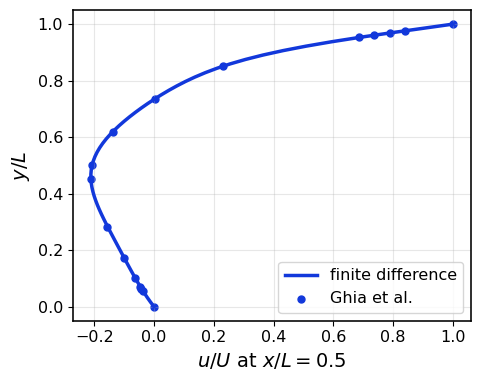

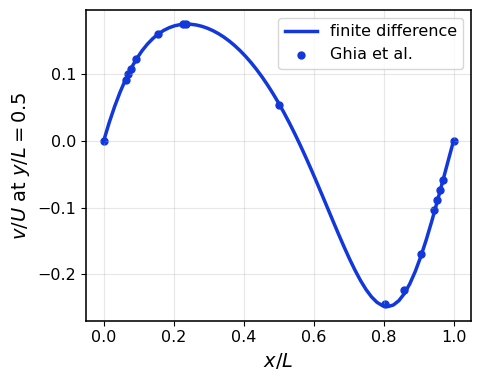

In [13]:
x, y, u_center, v_center = centerline_profiles(result)

plt.figure(figsize=(5, 4))
plt.plot(u_center, y, label="finite difference")
plt.scatter(GHIA_U, GHIA_Y, s=25, label="Ghia et al.")
plt.xlabel(r"$u/U$ at $x/L=0.5$")
plt.ylabel(r"$y/L$")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(5, 4))
plt.plot(x, v_center, label="finite difference")
plt.scatter(GHIA_X, GHIA_V, s=25, label="Ghia et al.")
plt.xlabel(r"$x/L$")
plt.ylabel(r"$v/U$ at $y/L=0.5$")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

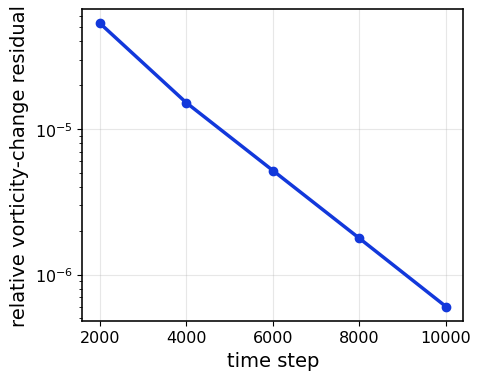

In [14]:
plt.figure(figsize=(5, 4))
plt.semilogy(result["residual_steps"], result["residual_values"], "o-")
plt.xlabel("time step")
plt.ylabel("relative vorticity-change residual")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

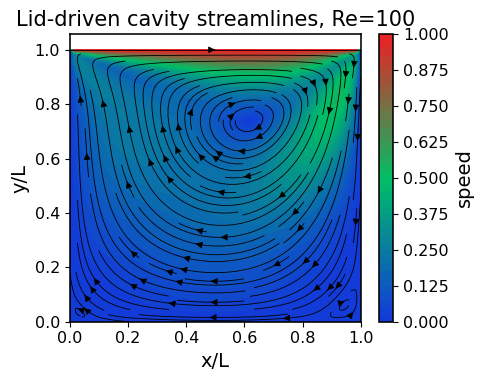

In [15]:
plt.figure(figsize=(5, 4))
speed = np.sqrt(result["u"]**2 + result["v"]**2)
plt.contourf(result["X"], result["Y"], speed, levels=40, cmap="cavity_rgb")
plt.colorbar(label="speed")
plt.streamplot(result["X"], result["Y"], result["u"], result["v"], density=1.3, linewidth=0.6, color="black")
plt.xlabel("x/L")
plt.ylabel("y/L")
plt.title("Lid-driven cavity streamlines, Re=100")
plt.tight_layout()
plt.show()

## 11. What students should learn from this solver

This solver is not meant to be the fastest cavity solver. It is meant to teach the structure of CFD:

1. The physical problem defines boundary conditions.
2. The PDE is rewritten in a numerically convenient form.
3. The domain is discretized on a grid.
4. Derivatives are approximated by finite differences.
5. Boundary conditions are applied carefully.
6. The solution is advanced or iterated.
7. A residual monitors convergence.
8. The final result is compared with benchmark data.

This is the foundation for AI in fluids. Later, the CFD solution can become:
- training data,
- validation data,
- input to a neural operator,
- a target for a surrogate model,
- a physics-informed residual test.

## 12. Required student deliverables

For this CFD assignment, submit:

1. A plot of $u/U$ along $x/L=0.5$ compared with Ghia.
2. A plot of $v/U$ along $y/L=0.5$ compared with Ghia.
3. A streamplot of the cavity flow.
4. The residual history.
5. The final relative errors $E_u$ and $E_v$.
6. A short explanation of the role of the streamfunction.
7. A short explanation of why wall vorticity boundary conditions matter.
8. A short paragraph explaining how this CFD dataset could later be used for machine learning.

Do not just submit screenshots. Explain what the code is doing.

## Article-output contract

<!-- MIE690A article-aligned validation v3 -->

**Role:** Figures 2 and 8: Ghia velocity centerlines and Botella--Peyret pressure validation.

All manuscript-facing figures must be generated from retained numerical/model outputs through the documented notebook or shared helper, saved under `results/`, and accompanied by machine-readable metrics. Do not redraw curves by eye or substitute a screenshot for a solver-to-reference comparison. The complete ownership table and exact output filenames are in [`ARTICLE_FIGURE_MAP.md`](../../ARTICLE_FIGURE_MAP.md).
